# Notebook dengan retained execution outputs
Outputs analisis berasal dari executed notebook asli, bukan pengukuran baru. Salinan ini mempertahankan penyesuaian path/environment yang dijelaskan di `../docs/NOTEBOOKS.md`. Original notebook tersimpan byte-identical di `../original_project/additional/`.


# OCR Identity-Signal Ablation
## PP-OCRv6 End-to-End vs PP-OCRv6 Detector + SVTRv2 Recognizer

**Ketolak Pacil — COMPFEST 18 Data Science Academy**

Eksperimen ini hanya menguji **identity-discriminative signal dari OCR text**.

```text
SAME RAW-RECTIFIED CARD
        │
        ├───────────────────────────────┐
        ▼                               ▼
USER STACK                      TEAMMATE STACK
PaddleOCR PP-OCRv6              PP-OCRv6 Medium detector
detector + recognizer           + OpenOCR SVTRv2 Server
        │                               │
        └───────────────┬───────────────┘
                        ▼
       shared char TF-IDF 2–5 gram
                  + SVD ≤ 96D
                        ▼
             identical image pairs
                        ▼
      SAME vs DIFFERENT identity AUC
```

**Tidak direrun:** routing, specialist extraction, Siamese, clustering, peer consensus.

### Fairness
Yang dibuat sama:
- 632 labeled images;
- raw rectified document geometry;
- identity label (`identity_group`);
- TF-IDF config;
- SVD basis;
- pair list;
- evaluation metrics.

Yang berubah hanya OCR text source.

> Ini adalah **OCR-stack comparison**, bukan pure recognizer-only causal ablation.

# 0. Kaggle Setup

Recommended:

```text
Accelerator : GPU T4 x1
Internet    : ON pada first run
```

Attach:
1. teammate dataset/bundle `compfest`;
2. original COMPfest image dataset.

Notebook membutuhkan dari teammate bundle:
- `results_v3_stable/ocr_raw.parquet`
- `results_v28_generic_unknown_peer_consensus/predictions_released.csv`

Tidak perlu E12/E14/Siamese artifacts.

In [1]:
# ============================================================
# 1. CONFIG
# ============================================================

RUN_MODE = "full"      # "smoke" or "full"
SMOKE_N = 12

SEED = 42
MAX_TFIDF_FEATURES = 18_000
SVD_MAX_COMPONENTS = 96

N_GROUP_RESAMPLES = 300
RESAMPLE_GROUP_FRACTION = 0.80

FORCE_OCR_RERUN = False
SAVE_FULL_PAIR_TABLE = True

print("RUN_MODE           :", RUN_MODE)
print("SVD_MAX_COMPONENTS :", SVD_MAX_COMPONENTS)

RUN_MODE           : full
SVD_MAX_COMPONENTS : 96


# 1. PaddleOCR Environment

Stack yang dipakai mengikuti notebook kamu sebelumnya:

```python
PaddleOCR(
    ocr_version="PP-OCRv6",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
```

Target:
- `paddleocr==3.7.0`
- `paddlepaddle-gpu==3.3.0`

**Jangan import `paddle` sebelum cell setup berikut.**

In [ ]:
# Environment check saja; tidak mengubah dependency secara otomatis.
import importlib.metadata as metadata
import subprocess
import sys
import os
import re
TARGET_PADDLE = "3.3.0"
TARGET_PADDLEOCR = "3.7.0"
def pkg_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None
current_paddle = pkg_version("paddlepaddle-gpu") or pkg_version("paddlepaddle")
if current_paddle != TARGET_PADDLE or pkg_version("paddleocr") != TARGET_PADDLEOCR:
    raise RuntimeError("Siapkan environment Paddle terpisah sesuai docs/REPRODUCIBILITY.md; notebook ini tidak mengganti shared dependencies.")
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "BOS"
print("Paddle stack version check: PASS")


In [3]:
# ============================================================
# 3. IMPORTS + DEVICE CHECK
# ============================================================

import ast
import json
import math
import time
import zipfile
import shutil
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from tqdm.auto import tqdm

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
)
from sklearn.preprocessing import normalize

import paddle
import paddleocr
from paddleocr import PaddleOCR

warnings.filterwarnings("ignore")
np.random.seed(SEED)

HAS_GPU = (
    paddle.is_compiled_with_cuda()
    and paddle.device.cuda.device_count() > 0
)

PADDLE_DEVICE = "gpu:0" if HAS_GPU else "cpu"

print("PaddlePaddle :", paddle.__version__)
print("PaddleOCR    :", paddleocr.__version__)
print("Device       :", PADDLE_DEVICE)

if PADDLE_DEVICE == "cpu":
    print("⚠ Full 632-image OCR will be slower on CPU.")

/usr/local/lib/python3.12/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PaddlePaddle : 3.3.0
PaddleOCR    : 3.7.0
Device       : gpu:0


In [ ]:
# ============================================================
# 4. WORKSPACE
# ============================================================

from pathlib import Path
import os
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "pipeline" / "run_v27.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari folder repository ini.")

SEARCH_ROOTS = [REPO_ROOT / "pipeline", REPO_ROOT / "data/private", REPO_ROOT / "original_project/dataset"]
if os.environ.get("OCR_DATASET_DIR"):
    SEARCH_ROOTS.insert(0, Path(os.environ["OCR_DATASET_DIR"]).expanduser().resolve())


WORK_DIR = (
    Path("/kaggle/working/ocr_identity_similarity_ablation")
    if Path("/kaggle/working").exists()
    else Path("./ocr_identity_similarity_ablation")
)

ARTIFACT_DIR = WORK_DIR / "_teammate_artifact"
RECTIFIED_DIR = WORK_DIR / "rectified_raw"
OUTPUT_DIR = WORK_DIR / "outputs"

for p in [WORK_DIR, ARTIFACT_DIR, RECTIFIED_DIR, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

OCR_CACHE = WORK_DIR / "ppocrv6_user_raw_ocr.csv"

print("WORK_DIR:", WORK_DIR)

WORK_DIR: /kaggle/working/ocr_identity_similarity_ablation


# 2. Load Teammate Frozen Evidence

Baseline teammate:
**PP-OCRv6 Medium detector (ONNX CPU) + OpenOCR SVTRv2 Server recognizer (PyTorch CUDA)**.

Kita memakai `ocr_raw.parquet` agar kedua stack dibandingkan pada **raw rectified input**, tanpa perlu menebak CLAHE/preprocessing parameters.

In [5]:
# ============================================================
# 5. AUTO-DISCOVER TEAMMATE FILES
# ============================================================

RAW_OCR_SUFFIX = "results_v3_stable/ocr_raw.parquet"
V28_SUFFIX = (
    "results_v28_generic_unknown_peer_consensus/"
    "predictions_released.csv"
)

def find_direct_by_suffix(suffix):
    suffix = suffix.replace("\\", "/")
    basename = Path(suffix).name

    for root in SEARCH_ROOTS:
        if not root.exists():
            continue

        for p in root.rglob(basename):
            if p.is_file() and str(p).replace("\\", "/").endswith(suffix):
                return p

    return None

def find_in_zip(suffix):
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue

        for zp in root.rglob("*.zip"):
            try:
                with zipfile.ZipFile(zp, "r") as z:
                    member = next(
                        (m for m in z.namelist() if m.endswith(suffix)),
                        None,
                    )
                    if member:
                        return zp, member
            except zipfile.BadZipFile:
                continue

    return None, None

def materialize(suffix, output_name):
    direct = find_direct_by_suffix(suffix)

    if direct is not None:
        print("Direct:", direct)
        return direct

    zp, member = find_in_zip(suffix)

    if zp is None:
        raise FileNotFoundError(
            f"Missing teammate artifact: {suffix}"
        )

    target = ARTIFACT_DIR / output_name

    if not target.exists():
        with zipfile.ZipFile(zp, "r") as z:
            with z.open(member) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)

    print("ZIP:", zp, "→", member)
    return target

TEAM_RAW_OCR_PATH = materialize(
    RAW_OCR_SUFFIX,
    "ocr_raw.parquet",
)

V28_PATH = materialize(
    V28_SUFFIX,
    "predictions_released_v28.csv",
)

Direct: /kaggle/input/datasets/orieabyanmaulana/ablation-test/compfest/compfest_academy_project/V27_REPRODUCIBLE_BUNDLE/results_v3_stable/ocr_raw.parquet
Direct: /kaggle/input/datasets/orieabyanmaulana/ablation-test/compfest/compfest_academy_project/V27_REPRODUCIBLE_BUNDLE/results_v28_generic_unknown_peer_consensus/predictions_released.csv


In [6]:
# ============================================================
# 6. LOAD 632 LABELED ROWS
# ============================================================

teammate_raw = pd.read_parquet(TEAM_RAW_OCR_PATH)

v28 = pd.read_csv(V28_PATH)

required_v28 = {
    "filename",
    "identity_group",
    "has_ground_truth",
    "corners",
    "rectified_width",
    "rectified_height",
    "document_family",
}

required_raw = {
    "filename",
    "ocr_text",
    "ocr_confidence",
}

assert required_v28.issubset(v28.columns)
assert required_raw.issubset(teammate_raw.columns)

labeled = (
    v28[v28["has_ground_truth"].fillna(False).astype(bool)]
    .copy()
    .sort_values("filename")
    .reset_index(drop=True)
)

assert len(labeled) == 632

team_labeled = (
    labeled[
        [
            "filename",
            "identity_group",
            "corners",
            "rectified_width",
            "rectified_height",
            "document_family",
        ]
    ]
    .merge(
        teammate_raw[
            ["filename", "ocr_text", "ocr_confidence"]
        ].rename(columns={
            "ocr_text": "ocr_text_teammate",
            "ocr_confidence": "ocr_conf_teammate",
        }),
        on="filename",
        how="left",
        validate="one_to_one",
    )
)

assert team_labeled["ocr_text_teammate"].notna().all()

sizes = team_labeled.groupby("identity_group").size()

print("Labeled images  :", len(team_labeled))
print("Identity groups :", team_labeled["identity_group"].nunique())
print("Repeated groups :", int((sizes >= 2).sum()))

display(
    team_labeled[
        [
            "filename",
            "identity_group",
            "document_family",
            "ocr_conf_teammate",
            "ocr_text_teammate",
        ]
    ].head()
)

Labeled images  : 632
Identity groups : 152
Repeated groups : 26


,filename,identity_group,document_family,ocr_conf_teammate,ocr_text_teammate
0,image_001.jpg,id_28700d2dd868,MYKAD,0.994075,KAD PENGENALAN\nMyKad\nMALAYSIA\n650211-11-504...
1,image_002.jpg,id_b66f2db6f2c1,MYKAD,0.943498,KAD PENGENALAN\nMALAYSIA\nMyKad\nIDENTITY CARD...
2,image_003.jpg,id_16faa8b3ba14,MYKAD,0.987187,KAD PENGENALAN\nMALAYSIA\nMyKad\nIDENTITY CARD...
3,image_004.jpg,id_09e825c5392c,GENERIC_ID,0.986262,KAD PENGE\nALAYSIA\nPEMASTAUTINETAP\nMyPR\n820...
4,image_005.jpg,id_09e825c5392c,GENERIC_ID,0.975328,KAD PENGE\nALAYSIA\nPEMASTAUTINETAP\nMyPR\n820...


# 3. Locate Original Images

In [7]:
# ============================================================
# 7. IMAGE DISCOVERY
# ============================================================

def build_image_index(required_filenames):
    required = set(required_filenames)
    found = {}
    valid_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

    for root in SEARCH_ROOTS:
        if not root.exists():
            continue

        for p in root.rglob("*"):
            if not p.is_file():
                continue
            if p.suffix.lower() not in valid_exts:
                continue

            if p.name in required and p.name not in found:
                found[p.name] = p

            if len(found) == len(required):
                return found

    return found

IMAGE_PATHS = build_image_index(team_labeled["filename"])

missing = sorted(
    set(team_labeled["filename"]) - set(IMAGE_PATHS)
)

print("Images found:", len(IMAGE_PATHS))

if missing:
    print("Missing examples:", missing[:20])
    raise FileNotFoundError(
        "Attach the original COMPfest image dataset."
    )

print("✅ All 632 labeled images located.")

Images found: 632
✅ All 632 labeled images located.


# 4. Reconstruct Raw Rectified Cards

No adaptive preprocessing is applied here.

```text
original photo
→ retained V28 corners
→ perspective rectification
→ RAW RECTIFIED CARD
```

In [8]:
# ============================================================
# 8. RECTIFICATION
# ============================================================

def parse_corners(value):
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except Exception:
            value = ast.literal_eval(value)

    arr = np.asarray(value, dtype=np.float32)

    if arr.size != 8:
        raise ValueError(f"Invalid corners: {arr.shape}")

    return arr.reshape(4, 2)

def reconstruct_raw_rectified(row):
    target = RECTIFIED_DIR / f"{Path(row.filename).stem}.png"

    if target.exists():
        return target

    image = cv2.imread(str(IMAGE_PATHS[row.filename]))

    if image is None:
        raise RuntimeError(f"Cannot read {row.filename}")

    src = parse_corners(row.corners)

    width = int(round(float(row.rectified_width)))
    height = int(round(float(row.rectified_height)))

    dst = np.asarray(
        [
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1],
        ],
        dtype=np.float32,
    )

    H = cv2.getPerspectiveTransform(src, dst)

    rectified = cv2.warpPerspective(
        image,
        H,
        (width, height),
    )

    if rectified is None or rectified.size == 0:
        raise RuntimeError(f"Rectification failed: {row.filename}")

    if not cv2.imwrite(str(target), rectified):
        raise RuntimeError(f"Failed saving: {target}")

    return target

run_frame = (
    team_labeled.head(SMOKE_N).copy()
    if RUN_MODE == "smoke"
    else team_labeled.copy()
)

paths = []

for row in tqdm(
    run_frame.itertuples(index=False),
    total=len(run_frame),
    desc="Rectifying",
):
    paths.append(
        str(reconstruct_raw_rectified(row))
    )

run_frame["rectified_raw_path"] = paths

print("Rectified:", len(run_frame))

Rectifying:   0%|          | 0/632 [00:00<?, ?it/s]

Rectified: 632


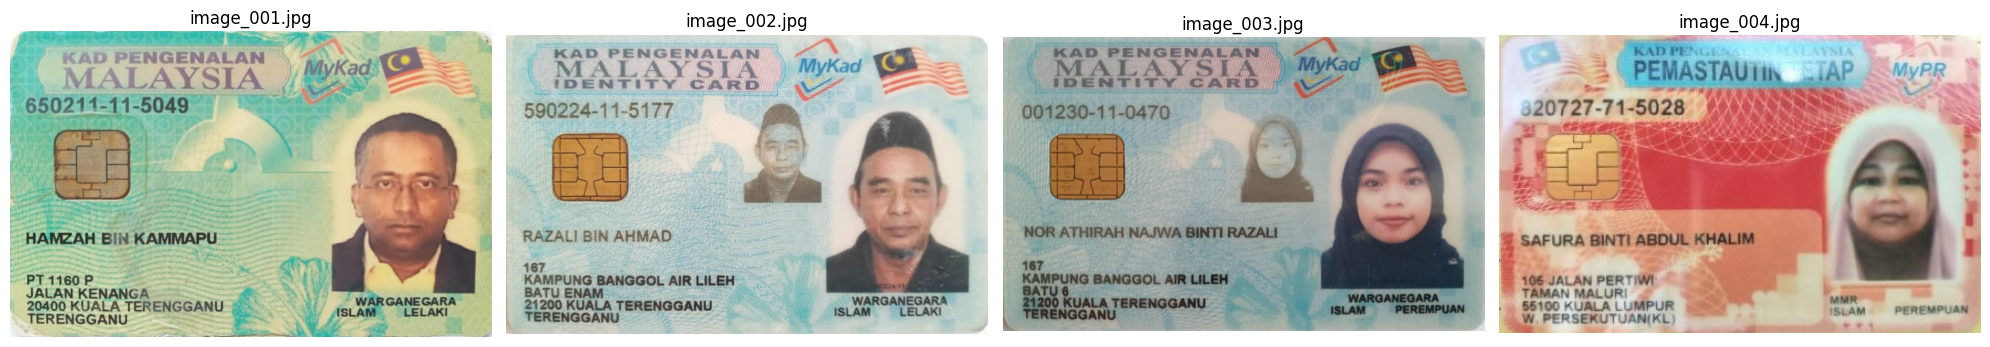

In [9]:
# ============================================================
# 9. RECTIFICATION SANITY CHECK
# ============================================================

preview = run_frame.head(min(4, len(run_frame)))

fig, axes = plt.subplots(
    1,
    len(preview),
    figsize=(5 * len(preview), 4),
)

if len(preview) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, preview.iterrows()):
    image = cv2.imread(row["rectified_raw_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(row["filename"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Initialize Your PP-OCRv6 Stack

In [10]:
# ============================================================
# 10. INITIALIZE PP-OCRv6
# ============================================================

ppocr_model = PaddleOCR(
    ocr_version="PP-OCRv6",
    device=PADDLE_DEVICE,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

print("✅ PP-OCRv6 initialized on", PADDLE_DEVICE)

Creating model: ('PP-OCRv6_medium_det', None, None)
Connectivity check to the model hoster has been skipped because `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` is enabled.
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Connecting to https://paddle-model-ecology.bj.bcebos.com/paddlex/official_inference_model/paddle3.0.0/PP-OCRv6_medium_det_infer.tar ...
[==================================================] 100.00%
Extracting PP-OCRv6_medium_det_infer.tar
[==================================================] 100.00%
Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.
Connecting to https://paddle-model-ecology.bj.bcebos.com/paddlex/official_inference_model/paddle3.0.0/PP-OCRv6_medium_rec_infer.tar ...
[========================

✅ PP-OCRv6 initialized on gpu:0


In [11]:
# ============================================================
# 11. INFERENCE WRAPPER
# ============================================================

def first_present(mapping, keys, default=None):
    for key in keys:
        if key in mapping and mapping[key] is not None:
            return mapping[key]
    return default

def ppocr_infer(image_input):
    started = time.perf_counter()

    results = ppocr_model.predict(image_input)

    texts = []
    confs = []

    for result in results:
        payload = result.json

        data = (
            payload.get("res", payload)
            if isinstance(payload, dict)
            else {}
        )

        rec_texts = first_present(
            data,
            ["rec_texts"],
            [],
        ) or []

        rec_scores = first_present(
            data,
            ["rec_scores"],
            [],
        ) or []

        texts.extend(
            str(x).strip()
            for x in rec_texts
            if str(x).strip()
        )

        for value in rec_scores:
            try:
                confs.append(float(value))
            except Exception:
                pass

    return {
        "ocr_text_user": "\n".join(texts),
        "ocr_conf_user": (
            float(np.mean(confs))
            if confs
            else np.nan
        ),
        "ocr_item_count_user": len(texts),
        "latency_s_user": time.perf_counter() - started,
    }

In [12]:
# ============================================================
# 12. OCR SMOKE TEST
# ============================================================

row = run_frame.iloc[0]

smoke = ppocr_infer(
    row["rectified_raw_path"]
)

print("Filename:", row["filename"])
print(smoke["ocr_text_user"][:1200])
print("Confidence:", smoke["ocr_conf_user"])
print("Regions   :", smoke["ocr_item_count_user"])
print("Latency s :", round(smoke["latency_s_user"], 3))

if not str(smoke["ocr_text_user"]).strip():
    raise RuntimeError("PP-OCRv6 smoke test returned empty text.")

print("✅ Smoke test PASS")

Filename: image_001.jpg
KAD PENGENALAN
MyKad
MALAYSIA
650211-11-5049
HAMZAH BIN KAMMAPU
PT1160P
JALANKENANGA
20400 KUALA TERENGGANU
WARGANEGARA
ISLAM
LELAKI
TERENGGANU
Confidence: 0.9968313624461492
Regions   : 12
Latency s : 0.879
✅ Smoke test PASS


# 6. Full PP-OCRv6 Run with Resume Cache

In [13]:
# ============================================================
# 13. OCR RUN
# ============================================================

if OCR_CACHE.exists() and not FORCE_OCR_RERUN:
    existing = pd.read_csv(OCR_CACHE)
else:
    existing = pd.DataFrame()

done = (
    set(existing["filename"])
    if "filename" in existing.columns
    else set()
)

records = (
    existing.to_dict("records")
    if not existing.empty
    else []
)

pending = run_frame[
    ~run_frame["filename"].isin(done)
].copy()

print("Cached :", len(done))
print("Pending:", len(pending))

for _, row in tqdm(
    pending.iterrows(),
    total=len(pending),
    desc="PP-OCRv6",
):
    error = ""

    try:
        out = ppocr_infer(
            row["rectified_raw_path"]
        )
    except Exception as exc:
        out = {
            "ocr_text_user": "",
            "ocr_conf_user": np.nan,
            "ocr_item_count_user": 0,
            "latency_s_user": np.nan,
        }
        error = f"{type(exc).__name__}: {exc}"

    records.append({
        "filename": row["filename"],
        **out,
        "error": error,
    })

    pd.DataFrame(records).to_csv(
        OCR_CACHE,
        index=False,
    )

user_ocr = (
    pd.DataFrame(records)
    .drop_duplicates("filename", keep="last")
    .sort_values("filename")
    .reset_index(drop=True)
)

active = user_ocr[
    user_ocr["filename"].isin(run_frame["filename"])
].copy()

assert len(active) == len(run_frame)

print("Rows      :", len(active))
print(
    "Errors    :",
    int(
        active["error"]
        .fillna("")
        .astype(str)
        .str.len()
        .gt(0)
        .sum()
    ),
)
print(
    "Mean sec/image:",
    round(active["latency_s_user"].dropna().mean(), 3),
)

Cached : 0
Pending: 632


PP-OCRv6:   0%|          | 0/632 [00:00<?, ?it/s]

Rows      : 632
Errors    : 0
Mean sec/image: 0.352


In [14]:
# ============================================================
# 14. OCR COVERAGE
# ============================================================

comparison = (
    run_frame[
        [
            "filename",
            "identity_group",
            "document_family",
            "ocr_text_teammate",
            "ocr_conf_teammate",
        ]
    ]
    .merge(
        active,
        on="filename",
        how="left",
        validate="one_to_one",
    )
)

comparison["user_has_text"] = (
    comparison["ocr_text_user"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
    .gt(0)
)

comparison["team_has_text"] = (
    comparison["ocr_text_teammate"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
    .gt(0)
)

coverage = pd.DataFrame([
    {
        "OCR Stack": "User — PaddleOCR PP-OCRv6",
        "Rows": len(comparison),
        "Non-empty OCR": int(comparison["user_has_text"].sum()),
        "Coverage (%)": 100 * comparison["user_has_text"].mean(),
        "Mean OCR Confidence": comparison["ocr_conf_user"].mean(),
    },
    {
        "OCR Stack": "Teammate — PP det + SVTRv2 rec",
        "Rows": len(comparison),
        "Non-empty OCR": int(comparison["team_has_text"].sum()),
        "Coverage (%)": 100 * comparison["team_has_text"].mean(),
        "Mean OCR Confidence": comparison["ocr_conf_teammate"].mean(),
    },
])

display(
    coverage.style
    .format({
        "Coverage (%)": "{:.2f}",
        "Mean OCR Confidence": "{:.4f}",
    })
    .hide(axis="index")
)

comparison.to_csv(
    OUTPUT_DIR / "ocr_stack_text_comparison.csv",
    index=False,
)

OCR Stack,Rows,Non-empty OCR,Coverage (%),Mean OCR Confidence
User — PaddleOCR PP-OCRv6,632,627,99.21,0.8453
Teammate — PP det + SVTRv2 rec,632,631,99.84,0.8109


# 7. Shared Character TF-IDF + SVD

Representation config mengikuti teammate identity-linking design:

```python
TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 5),
    min_df=1,
    max_features=18000,
    sublinear_tf=True,
)
→ TruncatedSVD(n_components <= 96)
```

Primary protocol memakai **shared representation space**:
- kedua OCR corpus digabung untuk unsupervised TF-IDF/SVD fit;
- tidak ada GT Name/DOB/Address sebagai feature;
- identity label hanya dipakai setelah embedding selesai untuk evaluasi pair.

In [15]:
# ============================================================
# 15. CLEAN OCR TEXT
# ============================================================

def clean_ocr_text(text):
    text = str(text or "")
    return re.sub(r"\s+", " ", text).strip()

comparison["text_user_clean"] = (
    comparison["ocr_text_user"]
    .fillna("")
    .map(clean_ocr_text)
)

comparison["text_team_clean"] = (
    comparison["ocr_text_teammate"]
    .fillna("")
    .map(clean_ocr_text)
)

assert comparison["identity_group"].notna().all()

In [16]:
# ============================================================
# 16. FIT SHARED SPACE
# ============================================================

n = len(comparison)

combined_texts = pd.concat(
    [
        comparison["text_team_clean"],
        comparison["text_user_clean"],
    ],
    ignore_index=True,
)

vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 5),
    min_df=1,
    max_features=MAX_TFIDF_FEATURES,
    sublinear_tf=True,
)

X_sparse = vectorizer.fit_transform(combined_texts)

n_components = min(
    SVD_MAX_COMPONENTS,
    X_sparse.shape[0] - 1,
    X_sparse.shape[1] - 1,
)

n_components = max(2, int(n_components))

svd = TruncatedSVD(
    n_components=n_components,
    random_state=SEED,
)

X_dense = svd.fit_transform(X_sparse)
X_dense = normalize(X_dense, norm="l2")

team_vec = X_dense[:n]
user_vec = X_dense[n:]

print("Vocabulary size :", len(vectorizer.vocabulary_))
print("SVD dimensions  :", n_components)
print(
    "Explained var   :",
    round(float(svd.explained_variance_ratio_.sum()), 4),
)

Vocabulary size : 18000
SVD dimensions  : 96
Explained var   : 0.6827


# 8. Full Identity Pair Evaluation

For 632 images:

```text
632 choose 2 = 199,396 pairs
```

Tidak perlu sampling pair; semua pair dievaluasi.

In [17]:
# ============================================================
# 17. IDENTICAL FULL PAIR LIST
# ============================================================

groups = comparison["identity_group"].astype(str).to_numpy()

row_i, row_j = np.triu_indices(
    len(comparison),
    k=1,
)

pair_label = (
    groups[row_i] == groups[row_j]
).astype(np.int8)

team_sim = np.sum(
    team_vec[row_i] * team_vec[row_j],
    axis=1,
)

user_sim = np.sum(
    user_vec[row_i] * user_vec[row_j],
    axis=1,
)

print("All pairs     :", len(pair_label))
print("Same identity :", int(pair_label.sum()))
print("Different     :", int((1 - pair_label).sum()))

assert pair_label.min() == 0
assert pair_label.max() == 1

All pairs     : 199396
Same identity : 5553
Different     : 193843


In [18]:
# ============================================================
# 18. CORE METRICS
# ============================================================

def best_balanced_threshold(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    balanced = (tpr + (1.0 - fpr)) / 2.0
    idx = int(np.nanargmax(balanced))
    return float(thresholds[idx]), float(balanced[idx])

def summarize_stack(name, y, scores):
    same = scores[y == 1]
    diff = scores[y == 0]

    threshold, bal_acc = best_balanced_threshold(
        y,
        scores,
    )

    return {
        "OCR Stack": name,
        "ROC-AUC": roc_auc_score(y, scores),
        "Average Precision": average_precision_score(y, scores),
        "Same Mean": same.mean(),
        "Same Median": np.median(same),
        "Different Mean": diff.mean(),
        "Different Median": np.median(diff),
        "Median Separation": np.median(same) - np.median(diff),
        "Best Threshold": threshold,
        "Best Balanced Accuracy": bal_acc,
    }

summary = pd.DataFrame([
    summarize_stack(
        "Teammate — PP-OCRv6 det + SVTRv2 rec",
        pair_label,
        team_sim,
    ),
    summarize_stack(
        "User — PaddleOCR PP-OCRv6 end-to-end",
        pair_label,
        user_sim,
    ),
])

display(
    summary.style
    .format({
        c: "{:.4f}"
        for c in summary.columns
        if c != "OCR Stack"
    })
    .hide(axis="index")
)

summary.to_csv(
    OUTPUT_DIR / "identity_similarity_summary.csv",
    index=False,
)

OCR Stack,ROC-AUC,Average Precision,Same Mean,Same Median,Different Mean,Different Median,Median Separation,Best Threshold,Best Balanced Accuracy
Teammate — PP-OCRv6 det + SVTRv2 rec,0.9357,0.7201,0.7045,0.8843,0.0794,0.0574,0.8270,0.2011,0.9205
User — PaddleOCR PP-OCRv6 end-to-end,0.9782,0.7937,0.7820,0.9301,0.0857,0.0659,0.8641,0.2351,0.9632


In [19]:
# ============================================================
# 19. FULL PAIR TABLE
# ============================================================

pair_table = pd.DataFrame({
    "filename_i": comparison.iloc[row_i]["filename"].to_numpy(),
    "filename_j": comparison.iloc[row_j]["filename"].to_numpy(),
    "identity_i": groups[row_i],
    "identity_j": groups[row_j],
    "same_identity": pair_label.astype(bool),
    "similarity_teammate": team_sim,
    "similarity_user_ppocrv6": user_sim,
    "delta_user_minus_teammate": user_sim - team_sim,
})

if SAVE_FULL_PAIR_TABLE:
    pair_table.to_csv(
        OUTPUT_DIR / "identity_similarity_all_pairs.csv",
        index=False,
    )

display(pair_table.head())

,filename_i,filename_j,identity_i,identity_j,same_identity,similarity_teammate,similarity_user_ppocrv6,delta_user_minus_teammate
0,image_001.jpg,image_002.jpg,id_28700d2dd868,id_b66f2db6f2c1,False,0.714796,0.776420,0.061624
1,image_001.jpg,image_003.jpg,id_28700d2dd868,id_16faa8b3ba14,False,0.812146,0.773461,-0.038685
2,image_001.jpg,image_004.jpg,id_28700d2dd868,id_09e825c5392c,False,0.206595,0.258700,0.052105
3,image_001.jpg,image_005.jpg,id_28700d2dd868,id_09e825c5392c,False,0.206595,0.251532,0.044937
4,image_001.jpg,image_006.jpg,id_28700d2dd868,id_6e869565aa2d,False,0.361314,0.353854,-0.007460


# 9. Visual Diagnostics

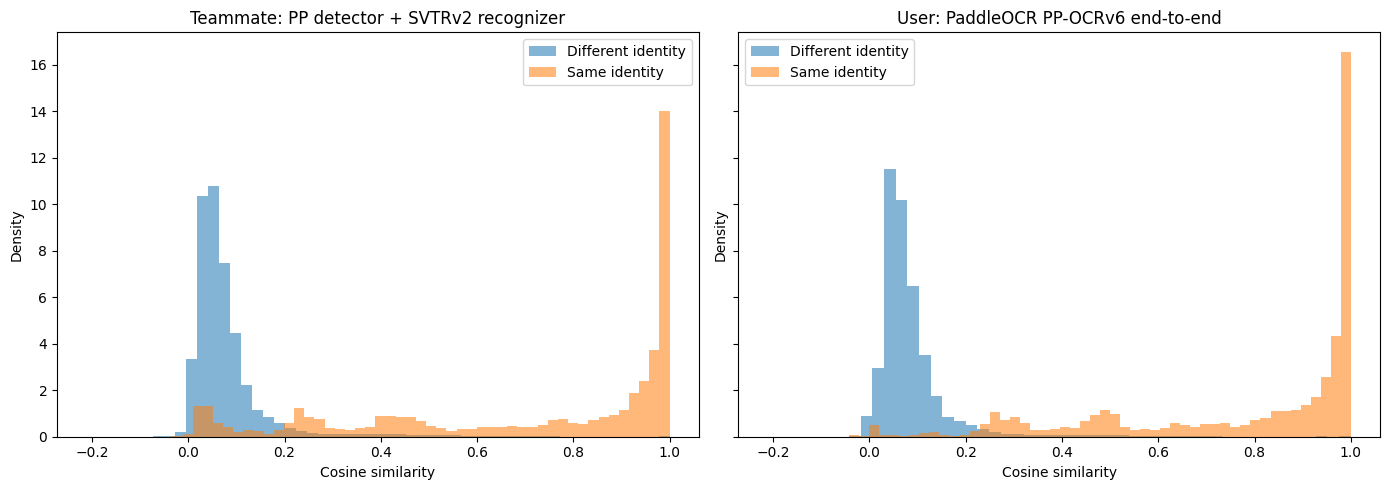

Saved: /kaggle/working/ocr_identity_similarity_ablation/outputs/01_similarity_distributions.png


In [20]:
# ============================================================
# 20. SIMILARITY DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
)

for ax, scores, title in [
    (
        axes[0],
        team_sim,
        "Teammate: PP detector + SVTRv2 recognizer",
    ),
    (
        axes[1],
        user_sim,
        "User: PaddleOCR PP-OCRv6 end-to-end",
    ),
]:
    ax.hist(
        scores[pair_label == 0],
        bins=50,
        density=True,
        alpha=0.55,
        label="Different identity",
    )
    ax.hist(
        scores[pair_label == 1],
        bins=50,
        density=True,
        alpha=0.55,
        label="Same identity",
    )
    ax.set_title(title)
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()

path = OUTPUT_DIR / "01_similarity_distributions.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", path)

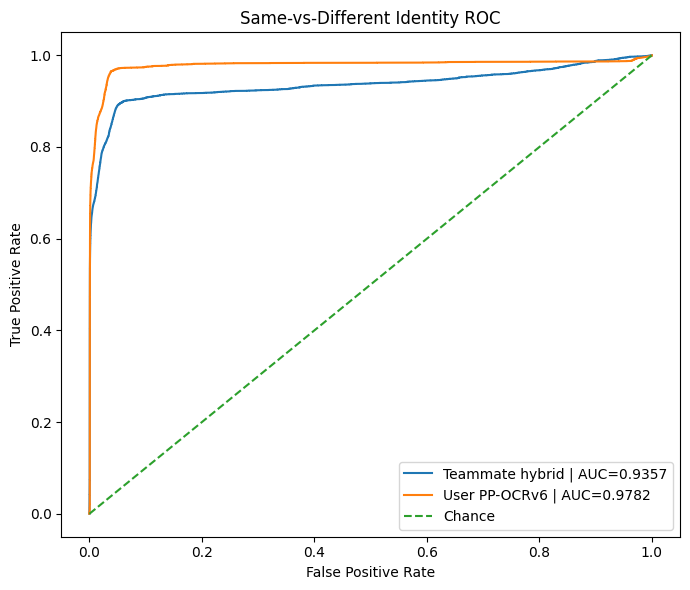

Saved: /kaggle/working/ocr_identity_similarity_ablation/outputs/02_roc_curve.png


In [21]:
# ============================================================
# 21. ROC CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

for scores, label in [
    (team_sim, "Teammate hybrid"),
    (user_sim, "User PP-OCRv6"),
]:
    fpr, tpr, _ = roc_curve(pair_label, scores)
    auc = roc_auc_score(pair_label, scores)

    ax.plot(
        fpr,
        tpr,
        label=f"{label} | AUC={auc:.4f}",
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Same-vs-Different Identity ROC")
ax.legend()

plt.tight_layout()

path = OUTPUT_DIR / "02_roc_curve.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", path)

OCR Stack,ROC-AUC,Average Precision,Median Separation,Best Balanced Accuracy
Teammate — PP-OCRv6 det + SVTRv2 rec,0.9357,0.7201,0.8270,0.9205
User — PaddleOCR PP-OCRv6 end-to-end,0.9782,0.7937,0.8641,0.9632


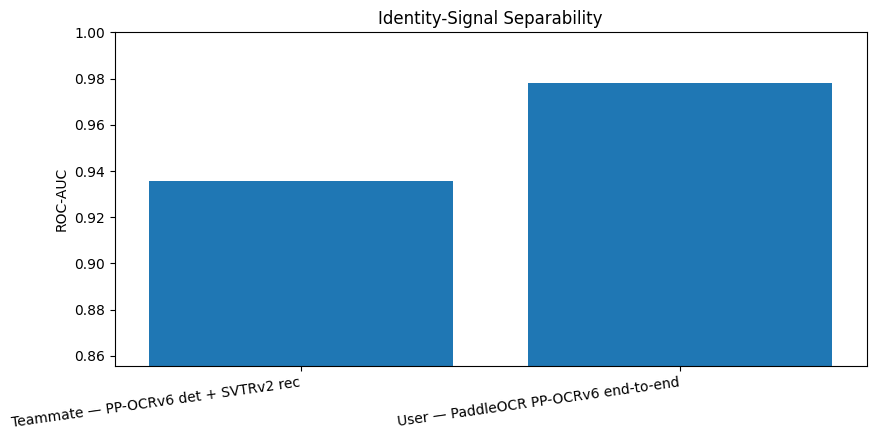

In [22]:
# ============================================================
# 22. AUC SCOREBOARD
# ============================================================

scoreboard = summary[
    [
        "OCR Stack",
        "ROC-AUC",
        "Average Precision",
        "Median Separation",
        "Best Balanced Accuracy",
    ]
].copy()

display(
    scoreboard.style
    .format({
        "ROC-AUC": "{:.4f}",
        "Average Precision": "{:.4f}",
        "Median Separation": "{:.4f}",
        "Best Balanced Accuracy": "{:.4f}",
    })
    .hide(axis="index")
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.bar(
    scoreboard["OCR Stack"],
    scoreboard["ROC-AUC"],
)

ax.set_ylim(
    max(0.0, scoreboard["ROC-AUC"].min() - 0.08),
    1.0,
)
ax.set_ylabel("ROC-AUC")
ax.set_title("Identity-Signal Separability")

plt.xticks(rotation=8, ha="right")
plt.tight_layout()

path = OUTPUT_DIR / "03_auc_scoreboard.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()

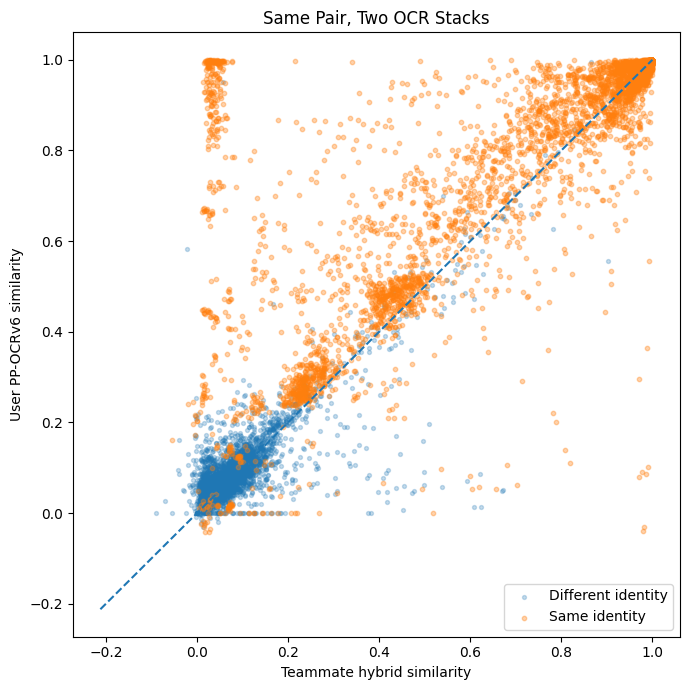

In [23]:
# ============================================================
# 23. PAIRED SIMILARITY SCATTER
# ============================================================

rng = np.random.default_rng(SEED)

same_idx = np.where(pair_label == 1)[0]
diff_idx = np.where(pair_label == 0)[0]

plot_same = rng.choice(
    same_idx,
    size=min(5000, len(same_idx)),
    replace=False,
)

plot_diff = rng.choice(
    diff_idx,
    size=min(5000, len(diff_idx)),
    replace=False,
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    team_sim[plot_diff],
    user_sim[plot_diff],
    s=8,
    alpha=0.25,
    label="Different identity",
)

ax.scatter(
    team_sim[plot_same],
    user_sim[plot_same],
    s=10,
    alpha=0.35,
    label="Same identity",
)

lo = min(team_sim.min(), user_sim.min())
hi = max(team_sim.max(), user_sim.max())

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
)

ax.set_xlabel("Teammate hybrid similarity")
ax.set_ylabel("User PP-OCRv6 similarity")
ax.set_title("Same Pair, Two OCR Stacks")
ax.legend()

plt.tight_layout()

path = OUTPUT_DIR / "04_pair_similarity_scatter.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()

# 10. Identity-Group Resampling Stability

Pair observations saling dependent karena satu image muncul di banyak pair.

Kita lakukan repeated **identity-group subsampling**:
- keep 80% identity groups;
- hitung AUC dua stack pada subset yang sama;
- simpan Δ AUC;
- ulang 300 kali.

Ini adalah **stability diagnostic**, bukan formal confidence interval.

In [24]:
# ============================================================
# 24. GROUP RESAMPLING
# ============================================================

unique_groups = np.unique(groups)
rng = np.random.default_rng(SEED)

rows = []

for b in tqdm(
    range(N_GROUP_RESAMPLES),
    desc="Identity-group resampling",
):
    k = max(
        2,
        int(
            math.ceil(
                RESAMPLE_GROUP_FRACTION
                * len(unique_groups)
            )
        ),
    )

    selected_groups = rng.choice(
        unique_groups,
        size=k,
        replace=False,
    )

    keep_images = np.isin(groups, selected_groups)

    keep_pairs = (
        keep_images[row_i]
        & keep_images[row_j]
    )

    y = pair_label[keep_pairs]

    if len(np.unique(y)) < 2:
        continue

    team_auc = roc_auc_score(
        y,
        team_sim[keep_pairs],
    )

    user_auc = roc_auc_score(
        y,
        user_sim[keep_pairs],
    )

    rows.append({
        "iteration": b,
        "n_groups": k,
        "n_images": int(keep_images.sum()),
        "n_pairs": int(keep_pairs.sum()),
        "auc_teammate": team_auc,
        "auc_user_ppocrv6": user_auc,
        "delta_auc_user_minus_teammate": user_auc - team_auc,
    })

resampling = pd.DataFrame(rows)

resampling.to_csv(
    OUTPUT_DIR / "identity_group_resampling.csv",
    index=False,
)

delta = resampling[
    "delta_auc_user_minus_teammate"
].dropna()

stability = pd.DataFrame([{
    "Metric": "Δ ROC-AUC (User − Teammate)",
    "Mean": delta.mean(),
    "Median": delta.median(),
    "2.5%": delta.quantile(0.025),
    "97.5%": delta.quantile(0.975),
    "P(Δ > 0)": (delta > 0).mean(),
    "Resamples": len(delta),
}])

display(
    stability.style
    .format({
        "Mean": "{:+.4f}",
        "Median": "{:+.4f}",
        "2.5%": "{:+.4f}",
        "97.5%": "{:+.4f}",
        "P(Δ > 0)": "{:.3f}",
    })
    .hide(axis="index")
)

stability.to_csv(
    OUTPUT_DIR / "auc_delta_stability_summary.csv",
    index=False,
)

Identity-group resampling:   0%|          | 0/300 [00:00<?, ?it/s]

Metric,Mean,Median,2.5%,97.5%,P(Δ > 0),Resamples
Δ ROC-AUC (User − Teammate),+0.0427,+0.0432,+0.0268,+0.0572,1.000,300


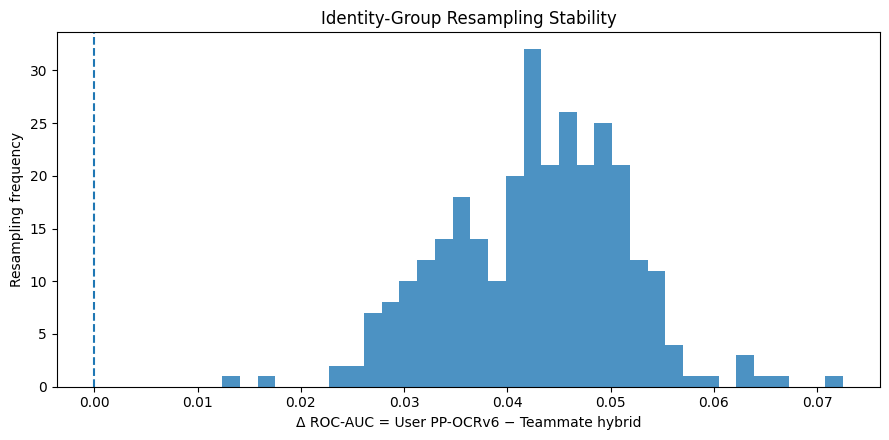

In [25]:
# ============================================================
# 25. RESAMPLING PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(
    delta,
    bins=35,
    alpha=0.8,
)

ax.axvline(
    0,
    linestyle="--",
)

ax.set_xlabel(
    "Δ ROC-AUC = User PP-OCRv6 − Teammate hybrid"
)
ax.set_ylabel("Resampling frequency")
ax.set_title("Identity-Group Resampling Stability")

plt.tight_layout()

path = OUTPUT_DIR / "05_auc_delta_resampling.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()

# 11. Qualitative Pair Examples

In [26]:
# ============================================================
# 26. TOP SAME-IDENTITY GAINS / LOSSES
# ============================================================

same_pairs = pair_table[
    pair_table["same_identity"]
].copy()

top_gain = same_pairs.nlargest(
    12,
    "delta_user_minus_teammate",
)

top_loss = same_pairs.nsmallest(
    12,
    "delta_user_minus_teammate",
)

print("TOP SAME-IDENTITY GAINS")
display(top_gain)

print("\nTOP SAME-IDENTITY LOSSES")
display(top_loss)

top_gain.to_csv(
    OUTPUT_DIR / "top_same_identity_gains.csv",
    index=False,
)

top_loss.to_csv(
    OUTPUT_DIR / "top_same_identity_losses.csv",
    index=False,
)

TOP SAME-IDENTITY GAINS


,filename_i,filename_j,identity_i,identity_j,same_identity,similarity_teammate,similarity_user_ppocrv6,delta_user_minus_teammate
192266,image_513.jpg,image_524.jpg,id_0d6f1f61d65b,id_0d6f1f61d65b,True,0.017652,0.998023,0.980371
151817,image_324.jpg,image_332.jpg,id_2af14934efb4,id_2af14934efb4,True,0.017042,0.995340,0.978297
153342,image_329.jpg,image_332.jpg,id_2af14934efb4,id_2af14934efb4,True,0.020384,0.997963,0.977579
193514,image_524.jpg,image_529.jpg,id_0d6f1f61d65b,id_0d6f1f61d65b,True,0.016112,0.992973,0.976861
161723,image_358.jpg,image_361.jpg,id_9501fc72ae01,id_9501fc72ae01,True,0.022588,0.999018,0.976430
148682,image_314.jpg,image_322.jpg,id_2af14934efb4,id_2af14934efb4,True,0.021103,0.995828,0.974724
162543,image_361.jpg,image_365.jpg,id_9501fc72ae01,id_9501fc72ae01,True,0.024342,0.998701,0.974360
192260,image_513.jpg,image_518.jpg,id_0d6f1f61d65b,id_0d6f1f61d65b,True,0.024267,0.998387,0.974120
151197,image_322.jpg,image_329.jpg,id_2af14934efb4,id_2af14934efb4,True,0.024218,0.997792,0.973574
149009,image_315.jpg,image_332.jpg,id_2af14934efb4,id_2af14934efb4,True,0.023882,0.996213,0.972332



TOP SAME-IDENTITY LOSSES


,filename_i,filename_j,identity_i,identity_j,same_identity,similarity_teammate,similarity_user_ppocrv6,delta_user_minus_teammate
168520,image_384.jpg,image_385.jpg,id_30131854e50d,id_30131854e50d,True,0.979823,-0.040358,-1.020181
166252,image_375.jpg,image_385.jpg,id_30131854e50d,id_30131854e50d,True,0.981038,-0.030047,-1.011085
169507,image_388.jpg,image_390.jpg,id_30131854e50d,id_30131854e50d,True,0.985799,0.086103,-0.899696
168525,image_384.jpg,image_390.jpg,id_30131854e50d,id_30131854e50d,True,0.970787,0.078658,-0.892129
166257,image_375.jpg,image_390.jpg,id_30131854e50d,id_30131854e50d,True,0.991017,0.102675,-0.888341
168770,image_385.jpg,image_388.jpg,id_30131854e50d,id_30131854e50d,True,0.976911,0.090590,-0.886321
181062,image_441.jpg,image_444.jpg,id_3d73590bf228,id_3d73590bf228,True,0.819458,0.111516,-0.707943
166255,image_375.jpg,image_388.jpg,id_30131854e50d,id_30131854e50d,True,0.971217,0.295966,-0.675251
181069,image_441.jpg,image_451.jpg,id_3d73590bf228,id_3d73590bf228,True,0.792155,0.117061,-0.675094
181060,image_441.jpg,image_442.jpg,id_3d73590bf228,id_3d73590bf228,True,0.808070,0.138569,-0.669500


In [27]:
# ============================================================
# 27. OCR TEXT EXAMPLES
# ============================================================

text_lookup = comparison.set_index("filename")

example_rows = []

for direction, frame in [
    ("gain", top_gain.head(6)),
    ("loss", top_loss.head(6)),
]:
    for _, pair in frame.iterrows():
        fi = pair["filename_i"]
        fj = pair["filename_j"]

        example_rows.append({
            "direction": direction,
            "filename_i": fi,
            "filename_j": fj,
            "team_similarity": pair["similarity_teammate"],
            "user_similarity": pair["similarity_user_ppocrv6"],
            "delta": pair["delta_user_minus_teammate"],
            "team_text_i": text_lookup.at[fi, "ocr_text_teammate"],
            "team_text_j": text_lookup.at[fj, "ocr_text_teammate"],
            "user_text_i": text_lookup.at[fi, "ocr_text_user"],
            "user_text_j": text_lookup.at[fj, "ocr_text_user"],
        })

examples = pd.DataFrame(example_rows)

display(examples)

examples.to_csv(
    OUTPUT_DIR / "qualitative_pair_examples.csv",
    index=False,
)

,direction,filename_i,filename_j,team_similarity,user_similarity,delta,team_text_i,team_text_j,user_text_i,user_text_j
0,gain,image_513.jpg,image_524.jpg,0.017652,0.998023,0.980371,N\nFORERKORT\nNORGE\n1.FJELD\n2.HANS·PETTER\n3...,TIE\nT\nP\n上\nE\n二\nA\n1\n7,FORERKORT\nNORGE\n1. FJELD\n2. HANS-PETTER\n19...,N\nFORERKORT\nNORGE\n1. FJELD\n2. HANS-PETTER\...
1,gain,image_324.jpg,image_332.jpg,0.017042,0.995340,0.978297,AJOKORTTIKORKORT\nSUOMI\n:FIN.\nDriing Licance...,1\nEN\n上\nM\n1\nT\n宣\nMAC,AJOKORTTIKÖRKORT\nSUOMI\nFIN\nDriving Licance ...,AJOKORTTI KÖRKORT\nSUOMI\nFIN\nDriving Licence...
2,gain,image_329.jpg,image_332.jpg,0.020384,0.997963,0.977579,AJOKORTTIKORKORT\nSUOMI\n:FIN.\nDriving Licand...,1\nEN\n上\nM\n1\nT\n宣\nMAC,AJOKORTTIKÖRKORT\nSUOMI\nFIN\nDriving Licance ...,AJOKORTTI KÖRKORT\nSUOMI\nFIN\nDriving Licence...
3,gain,image_524.jpg,image_529.jpg,0.016112,0.992973,0.976861,TIE\nT\nP\n上\nE\n二\nA\n1\n7,N\nFORERKORT\nNORGE\n1.FJELD\n2.HANS-PETTER\n3...,N\nFORERKORT\nNORGE\n1. FJELD\n2. HANS-PETTER\...,N\nFORERKORT\nNORGE\n1. FJELD\n2. HANS-PETTER\...
4,gain,image_358.jpg,image_361.jpg,0.022588,0.999018,0.976430,HELLAS\nTuTroc/Type\nXwpa/Country\nAp.AraBarmp...,C\n1\nTN\nFS\n1\nT\nLE\n日\n不\n1\n1\nC\nT\nM\nC...,HELLAS\nTumoç/Type\nXwpa/Country\nAp. ∆iaßampl...,HELLAS\nTúnoç/Type\nXwpa/Country\nAp. ΔiaBainp...
5,gain,image_314.jpg,image_322.jpg,0.021103,0.995828,0.974724,AJOKORTTIKORKORT\nSUOMI\n:FIN.\nUeivieg Lleane...,R\n1\nEN\n1\n寄\nAC,AJOKORTTIKORKORT\nSUOMI\n:FIN`\nSieivieg Lisan...,AJOKORTTIKORKORT\nSUOMI\nFIN\nDriving Licance ...
6,loss,image_384.jpg,image_385.jpg,0.979823,-0.040358,-1.020181,1\nC\nC\nE\n1\nN\nHR,1\n1\nC\nT\nE\n1\nHR,HR:,0
7,loss,image_375.jpg,image_385.jpg,0.981038,-0.030047,-1.011085,1\n1\nP\nT\nD\nHR,1\n1\nC\nT\nE\n1\nHR,HR\n1,0
8,loss,image_388.jpg,image_390.jpg,0.985799,0.086103,-0.899696,1\n1\n1\nS\nC\nC\nHR,1\n1\nC\nT\n1\nHR,CHR:\n71\nknnr,R
9,loss,image_384.jpg,image_390.jpg,0.970787,0.078658,-0.892129,1\nC\nC\nE\n1\nN\nHR,1\n1\nC\nT\n1\nHR,HR:,R


# 12. Interpretation Guardrail

### Jika User PP-OCRv6 AUC lebih tinggi
PP-OCRv6 end-to-end mempertahankan identity-discriminative OCR signal lebih kuat pada raw rectified input.

### Jika hampir sama
Hybrid PP-detector + SVTRv2 mempertahankan identity signal yang comparable; ini bisa mendukung engineering trade-off karena detector/recognizer dipisah.

### Jika teammate hybrid lebih tinggi
Hybrid front-end memberi separability lebih kuat pada protocol ini.

**Jangan simpulkan eksperimen ini sebagai:**
- final field accuracy;
- routing accuracy;
- bukti SVTRv2 selalu lebih baik/buruk;
- pure recognizer-only ablation.

In [28]:
# ============================================================
# 28. AUTOMATIC READOUT
# ============================================================

team_auc = float(
    summary.loc[
        summary["OCR Stack"].str.startswith("Teammate"),
        "ROC-AUC",
    ].iloc[0]
)

user_auc = float(
    summary.loc[
        summary["OCR Stack"].str.startswith("User"),
        "ROC-AUC",
    ].iloc[0]
)

delta_auc = user_auc - team_auc

if delta_auc >= 0.01:
    verdict = (
        "USER PP-OCRv6 RETAINS STRONGER IDENTITY SIGNAL "
        "under this diagnostic."
    )
elif delta_auc <= -0.01:
    verdict = (
        "TEAMMATE HYBRID RETAINS STRONGER IDENTITY SIGNAL "
        "under this diagnostic."
    )
else:
    verdict = (
        "IDENTITY SIGNAL IS BROADLY COMPARABLE "
        "between the two OCR stacks."
    )

decision = pd.DataFrame([{
    "Teammate ROC-AUC": team_auc,
    "User PP-OCRv6 ROC-AUC": user_auc,
    "Δ AUC User − Teammate": delta_auc,
    "Diagnostic Verdict": verdict,
}])

display(
    decision.style
    .format({
        "Teammate ROC-AUC": "{:.4f}",
        "User PP-OCRv6 ROC-AUC": "{:.4f}",
        "Δ AUC User − Teammate": "{:+.4f}",
    })
    .hide(axis="index")
)

decision.to_csv(
    OUTPUT_DIR / "final_diagnostic_decision.csv",
    index=False,
)

print(verdict)

Teammate ROC-AUC,User PP-OCRv6 ROC-AUC,Δ AUC User − Teammate,Diagnostic Verdict
0.9357,0.9782,+0.0425,USER PP-OCRv6 RETAINS STRONGER IDENTITY SIGNAL under this diagnostic.


USER PP-OCRv6 RETAINS STRONGER IDENTITY SIGNAL under this diagnostic.


# 13. Export Experiment Bundle

In [29]:
# ============================================================
# 29. EXPORT ZIP
# ============================================================

metadata_out = {
    "experiment": "OCR identity-signal ablation",
    "user_stack": (
        "PaddleOCR 3.7.0 PP-OCRv6 end-to-end detector + recognizer"
    ),
    "teammate_stack": (
        "PP-OCRv6 Medium detector (ONNX CPU) "
        "+ OpenOCR SVTRv2 Server recognizer"
    ),
    "input_protocol": "raw rectified card",
    "labeled_images": int(len(comparison)),
    "identity_groups": int(
        comparison["identity_group"].nunique()
    ),
    "pair_count": int(len(pair_label)),
    "positive_pair_count": int(pair_label.sum()),
    "negative_pair_count": int((1 - pair_label).sum()),
    "representation": {
        "analyzer": "char_wb",
        "ngram_range": [2, 5],
        "max_features": MAX_TFIDF_FEATURES,
        "sublinear_tf": True,
        "svd_components": int(n_components),
        "shared_fit": True,
    },
    "run_mode": RUN_MODE,
    "paddle_device": PADDLE_DEVICE,
    "paddle_version": paddle.__version__,
    "paddleocr_version": paddleocr.__version__,
}

with open(
    OUTPUT_DIR / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metadata_out,
        f,
        indent=2,
        ensure_ascii=False,
    )

assets = []

for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        assets.append({
            "file": p.name,
            "size_kb": round(p.stat().st_size / 1024, 2),
        })

manifest = pd.DataFrame(assets)

manifest.to_csv(
    OUTPUT_DIR / "asset_manifest.csv",
    index=False,
)

display(manifest)

zip_base = (
    Path(
        "/kaggle/working/"
        "Ketolak_Pacil_OCR_Identity_Similarity_Ablation_Artifacts"
    )
    if Path("/kaggle/working").exists()
    else WORK_DIR
    / "Ketolak_Pacil_OCR_Identity_Similarity_Ablation_Artifacts"
)

zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=OUTPUT_DIR,
)

print("✅ DONE")
print("Output:", OUTPUT_DIR)
print("ZIP   :", zip_path)

,file,size_kb
0,01_similarity_distributions.png,75.71
1,02_roc_curve.png,108.91
2,03_auc_scoreboard.png,89.38
3,04_pair_similarity_scatter.png,429.64
4,05_auc_delta_resampling.png,59.87
5,auc_delta_stability_summary.csv,0.17
6,experiment_metadata.json,0.70
7,final_diagnostic_decision.csv,0.21
8,identity_group_resampling.csv,22.56
9,identity_similarity_all_pairs.csv,24695.79


✅ DONE
Output: /kaggle/working/ocr_identity_similarity_ablation/outputs
ZIP   : /kaggle/working/Ketolak_Pacil_OCR_Identity_Similarity_Ablation_Artifacts.zip


# What to Send Back

Setelah run, kirim salah satu:

**Paling gampang:**  
`Ketolak_Pacil_OCR_Identity_Similarity_Ablation_Artifacts.zip`

Atau screenshot:
1. OCR Coverage
2. Core Metrics
3. Similarity Distributions
4. ROC Curve
5. Group Resampling Stability
6. Automatic Readout

Baru setelah hasil keluar kita tulis justification recognizer-nya secara evidence-based.